In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
num_samples = 1000

cape_j_kg = np.random.uniform(500, 4000, num_samples)
temperature_c = np.random.uniform(15, 45, num_samples)
humidity_percent = np.random.uniform(40, 100, num_samples)
aerosol_optical_depth = np.random.uniform(0.1, 1.5, num_samples) # Represents dust/particles

lightning_strikes = (
    (cape_j_kg * 0.015) +
    (temperature_c * 1.2) +
    (humidity_percent * 0.5) +
    (aerosol_optical_depth * 10) +
    np.random.normal(0, 15, num_samples) # Natural atmospheric noise
)
lightning_strikes = np.maximum(0, lightning_strikes)

df = pd.DataFrame({
    'CAPE (J/kg)': cape_j_kg,
    'Temperature (°C)': temperature_c,
    'Humidity (%)': humidity_percent,
    'Aerosol Depth': aerosol_optical_depth,
    'Lightning_Count': lightning_strikes
})

In [2]:
X = df.drop('Lightning_Count', axis=1)
y = df['Lightning_Count']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

Showcase generated! Check 'lightning_correlation_results.png'


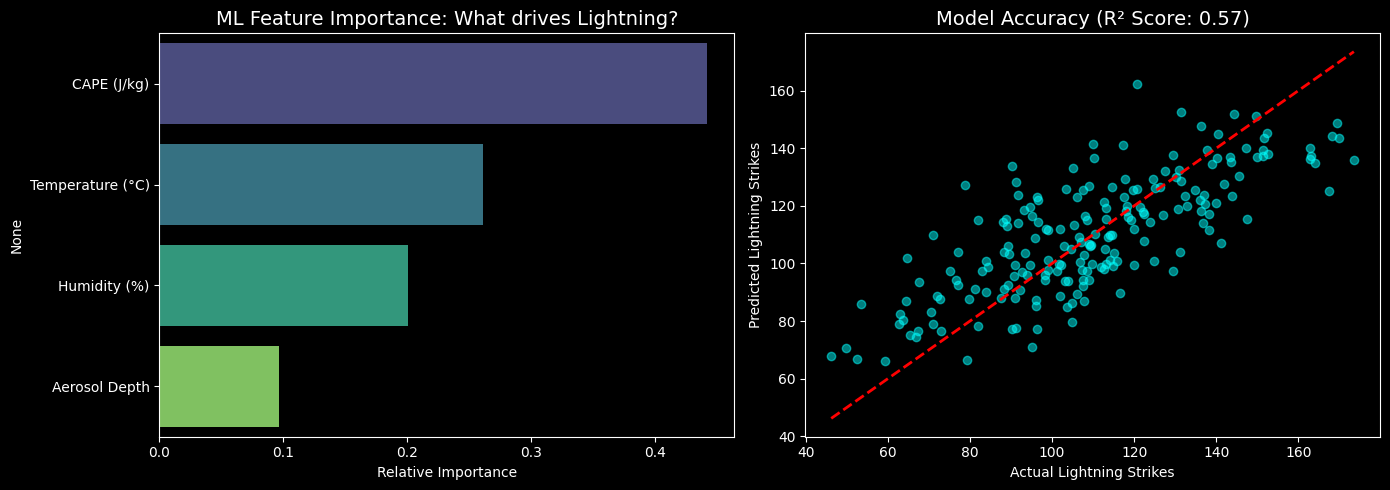

In [4]:
plt.style.use('dark_background')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Feature Importance
importances = model.feature_importances_
sns.barplot(x=importances, y=X.columns, ax=ax1, hue=X.columns, palette='viridis',  legend=False )
ax1.set_title('ML Feature Importance: What drives Lightning?', fontsize=14)
ax1.set_xlabel('Relative Importance')

# Plot 2: Actual vs Predicted
ax2.scatter(y_test, y_pred, alpha=0.5, color='cyan')
ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax2.set_title(f'Model Accuracy (R² Score: {r2:.2f})', fontsize=14)
ax2.set_xlabel('Actual Lightning Strikes')
ax2.set_ylabel('Predicted Lightning Strikes')

plt.tight_layout()
plt.savefig('lightning_correlation_results.png', dpi=300)
print("Showcase generated! Check 'lightning_correlation_results.png'")